This notebook is meant to load the UNet model so new images can be compared without having to rerun the model.

***Please note:  <b><i> You will need to set the root, dataset and dataset new names in the first cell.  You will need to save the new images to the location you've chosen for dataset_new_path.

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
import shutil
from pathlib import Path
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"
#set the images size and the path where the images live

img_size=(256,256)
im_width=256 
im_height=256
dataset_root='C:/Users/jenni/Documents/MSDS/MSDS621/'
dataset_path = dataset_root+'lgg-mri-segmentation/'
dataset_new_path=dataset_root+'new_image'

In [2]:
def data_generator(data_frame, batch_size=16):
    while True:
        for i in range(0, len(data_frame), batch_size):
            batch_df = data_frame[i:i+batch_size]
            images = []
            masks = []
            
            for index, row in batch_df.iterrows():
               
                img = cv2.imread(row['image_path'])
                img = cv2.resize(img, (im_width, im_height))
                img = img / 255.0  # Normalization
                
            
                mask = cv2.imread(row['mask_path'], cv2.IMREAD_GRAYSCALE)
                mask = cv2.resize(mask, (im_width, im_height))
                mask = mask / 255.0
                mask = np.expand_dims(mask, axis=-1) # (256, 256, 1)
                
                images.append(img)
                masks.append(mask)
                
            yield np.array(images), np.array(masks)

In [3]:
from tensorflow.keras import backend as K
import keras
# (Fixed Metrics) ---
#the dice coefficient--measures how similar or overlapping two sets or regions are, returning a value from 0 (no overlap) to 1 (identical / complete overlap).
def dice_coef(y_true, y_pred, smooth=1):
    
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

#the iou coefficient--measures how much two regions or sets overlap
def iou_coef(y_true, y_pred, smooth=1):
    
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    
    intersection = K.sum(K.abs(y_true * y_pred), axis=[1,2,3])
    union = K.sum(y_true,[1,2,3])+K.sum(y_pred,[1,2,3])-intersection
    return K.mean((intersection + smooth) / (union + smooth), axis=0)

model = keras.models.load_model(
    dataset_root+'/unet_brain_mri.keras', custom_objects={"dice_coef": dice_coef, "iou_coef": iou_coef}
)

In [4]:
image_path = []
mask_path = []

source_folder = Path(dataset_new_path)
dest_folder = Path(dataset_new_path)
#dest_folder.mkdir(exist_ok=True)  # Creates destination folder if it doesn't exist

suffix_to_append = "_mask"
valid_extensions = {".jpg", ".jpeg", ".png", ".webp",".tif"}


# 1. Create mask copies
for file_path in source_folder.iterdir():
    # Changed 'filename' to 'file_path.name'
    if (
        file_path.is_file()
        and 'mask' not in file_path.name
        and file_path.suffix.lower() in valid_extensions
    ):
        new_name = f"{file_path.stem}{suffix_to_append}{file_path.suffix}"
        shutil.copy2(file_path, dest_folder / new_name)

# 2. Build the DataFrame
for dirpath, dirnames, filenames in os.walk(dataset_new_path):
    for filename in filenames:
        ext = os.path.splitext(filename)[1].lower()
        if 'mask' not in filename and ext in valid_extensions:
            img_full_path = os.path.join(dirpath, filename)
            mask_filename = filename.replace(ext, f"{suffix_to_append}{ext}")
            mask_full_path = os.path.join(dirpath, mask_filename)

            image_path.append(img_full_path)
            mask_path.append(mask_full_path)

df1 = pd.DataFrame(data={'image_path': image_path, 'mask_path': mask_path})

In [6]:
def predict_and_draw_bbox(row):
    img_path = row['image_path']
    img = cv2.imread(img_path)
    img = cv2.resize(img, (im_width, im_height))
    img_norm = img / 255.0
    img_input = np.expand_dims(img_norm, axis=0)
    
    # Segmentation)
    pred_mask = model.predict(img_input)
    pred_mask = (pred_mask > 0.5).astype(np.uint8)[0, :, :, 0] # Binary
    
    # إContours
    contours, _ = cv2.findContours(pred_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) 
    
    # (Bounding Box)
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w > 5 and h > 5: 
            cv2.rectangle(img_rgb, (x, y), (x+w, y+h), (255, 0, 0), 2) # RGB)
    
    return img_rgb, pred_mask

This section counts the number of files in the new dataset path, then passes that in to the model.  

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step


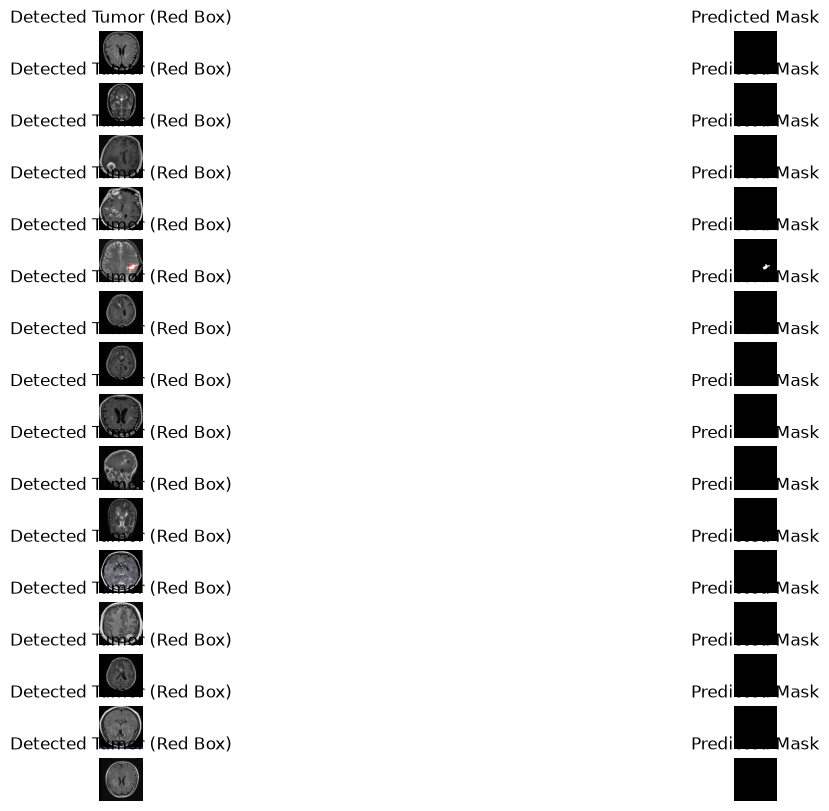

In [13]:
from pathlib import Path
folder = Path(dataset_new_path)
#for item in folder.iterdir():
   
file_count = sum(1 for item in folder.iterdir() if item.is_file())

samples1 = df1.sample(file_count)
plt.figure(figsize=(15, 10))

for i, (_, row) in enumerate(samples1.iterrows()):
    result_img, result_mask = predict_and_draw_bbox(row)
    
    plt.subplot(file_count, 2, 2*i + 1)
    plt.imshow(result_img)
    plt.title("Detected Tumor (Red Box)")
    plt.axis('off')
    
    plt.subplot(file_count, 2, 2*i + 2)
    plt.imshow(result_mask, cmap='gray')
    plt.title("Predicted Mask")
    plt.axis('off')

plt.show()